# 05 · Previsões com o modelo vigente e comparação de ciclos

- Carrega `models/modelo_vigente.json` e o modelo serializado, que já traz o pré-processamento e a lista de features.
- Gera previsões para o **conjunto de teste reservado**, que nunca foi usado para escolher modelos, features ou promoção.
- Compara os ciclos (histórico local e MLflow).

In [1]:
import sys
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import warnings
warnings.filterwarnings("ignore")
import json
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image

from src.utils import preparar_ambiente, carregar_config, carregar_contexto, salvar_contexto, dir_evidencias, configurar_mlflow
preparar_ambiente()
cfg = carregar_config()
pd.set_option("display.width", 160)

In [2]:
import joblib
from src.ingestao import carregar_holdout
from src.modelagem import metricas
from src.promocao import carregar_manifesto, HISTORICO_CICLOS

ctx = carregar_contexto()
ev = dir_evidencias(ctx["cycle_id"])
manifesto = carregar_manifesto()
modelo = joblib.load(RAIZ / manifesto["arquivo_modelo"])
_, teste = carregar_holdout(cfg)
alvo = cfg["dados"]["alvo"]

pred = modelo.predict(teste.drop(columns=[alvo]))
met_teste = metricas(teste[alvo], pred)
print(f"Modelo vigente: {manifesto['algoritmo']} (promovido no ciclo {manifesto['cycle_id']}, dados {manifesto['data_version']})")
print("Features usadas:", manifesto["features"])
print(f"TESTE reservado ({len(teste)} amostras): MAE={met_teste['mae']:.3f} MPa | RMSE={met_teste['rmse']:.3f} | R²={met_teste['r2']:.3f}")

saida = teste.copy()
saida["previsao"] = pred.round(2)
saida["erro_abs"] = (saida["previsao"] - saida[alvo]).abs().round(2)
saida.to_csv(ev / "previsoes_teste.csv", index=False)
display(saida.head(10))

Modelo vigente: random_forest (promovido no ciclo c20261122T215332Z-gh2, dados v2-fb30fed2)
Features usadas: ['aglomerante_total', 'log_idade', 'relacao_agua_cimento', 'relacao_agua_aglomerante', 'idade']
TESTE reservado (201 amostras): MAE=5.441 MPa | RMSE=7.324 | R²=0.820


,cimento,escoria,cinza_volante,agua,superplastificante,agregado_graudo,agregado_miudo,idade,resistencia,previsao,erro_abs
0,152.7,144.7,0.0,178.1,8.0,999.7,822.2,28,19.01,18.08,0.93
1,122.6,183.9,0.0,203.5,0.0,958.2,800.1,28,24.29,20.48,3.81
2,153.0,102.0,0.0,192.0,0.0,888.0,943.1,90,26.32,21.53,4.79
3,480.0,0.0,0.0,192.0,0.0,936.2,712.2,7,34.57,29.44,5.13
4,500.1,0.0,0.0,200.0,3.0,1124.4,613.2,28,44.13,41.58,2.55
5,212.0,141.3,0.0,203.5,0.0,973.4,750.0,28,33.00,27.27,5.73
6,102.0,153.0,0.0,192.0,0.0,887.0,942.0,28,17.28,20.07,2.79
7,239.6,359.4,0.0,185.7,0.0,941.6,664.3,7,25.42,28.26,2.84
8,213.7,0.0,174.7,154.8,10.2,1053.5,776.4,14,33.73,27.51,6.22
9,374.0,189.2,0.0,170.1,10.1,926.1,756.7,3,34.40,29.57,4.83


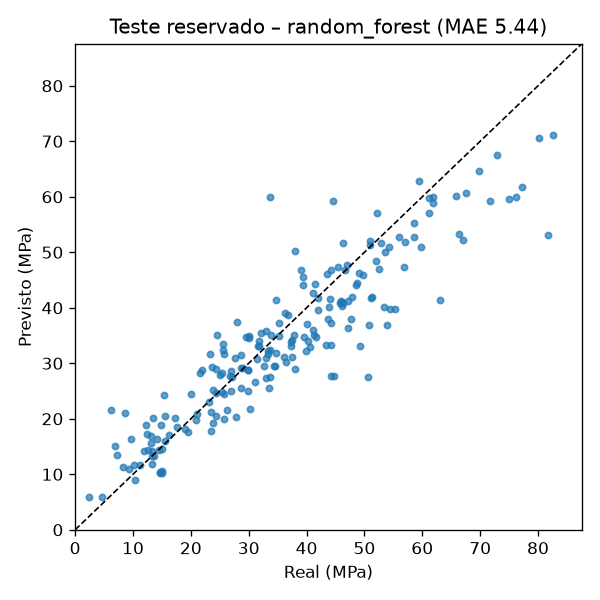

Previsão para nova mistura: 38.3 MPa


In [3]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(teste[alvo], pred, s=14, alpha=0.7)
lim = [0, max(teste[alvo].max(), pred.max()) + 5]
ax.plot(lim, lim, "k--", lw=1); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Real (MPa)"); ax.set_ylabel("Previsto (MPa)")
ax.set_title(f"Teste reservado – {manifesto['algoritmo']} (MAE {met_teste['mae']:.2f})")
fig.tight_layout(); fig.savefig(ev / "previsto_vs_real.png", dpi=120); plt.close(fig)
display(Image(str(ev / "previsto_vs_real.png")))

# Exemplo de uso: previsão para uma nova mistura (traço típico, 28 dias)
nova = pd.DataFrame([{"cimento": 350, "escoria": 100, "cinza_volante": 0, "agua": 180, "superplastificante": 6,
                      "agregado_graudo": 970, "agregado_miudo": 780, "idade": 28}])
print(f"Previsão para nova mistura: {modelo.predict(nova)[0]:.1f} MPa")

## Comparação entre ciclos

,cycle_id,gatilho,lote,data_version,n_treino,features_eleitas,mae_ridge,mae_random_forest,vencedor,mae_vigente_antes,decisao,vigente_apos,drift_alerta
0,c20261122T161514Z-gh1,workflow_dispatch,lote_01.csv,v1-91bac956,336,aglomerante_total|relacao_agua_cimento|log_ida...,7.7944,5.3311,random_forest,NaN,promovido,random_forest@c20261122T161514Z-gh1,False
1,c20261122T215332Z-gh2,schedule,lote_02.csv,v2-fb30fed2,436,aglomerante_total|log_idade|relacao_agua_cimen...,7.9036,4.9382,random_forest,5.3311,promovido,random_forest@c20261122T215332Z-gh2,False


Histórico recuperado do MLflow (runs de treino):


,cycle_id,data_version,algoritmo,val_mae,cv_mae,resultado
0,c20261122T161514Z-gh1,v1-91bac956,ridge,7.794440,5.497796,perdeu
1,c20261122T161514Z-gh1,v1-91bac956,random_forest,5.331081,4.979117,promovido
2,c20261122T215332Z-gh2,v2-fb30fed2,ridge,7.903561,5.450384,perdeu
3,c20261122T215332Z-gh2,v2-fb30fed2,random_forest,4.938242,4.667272,promovido


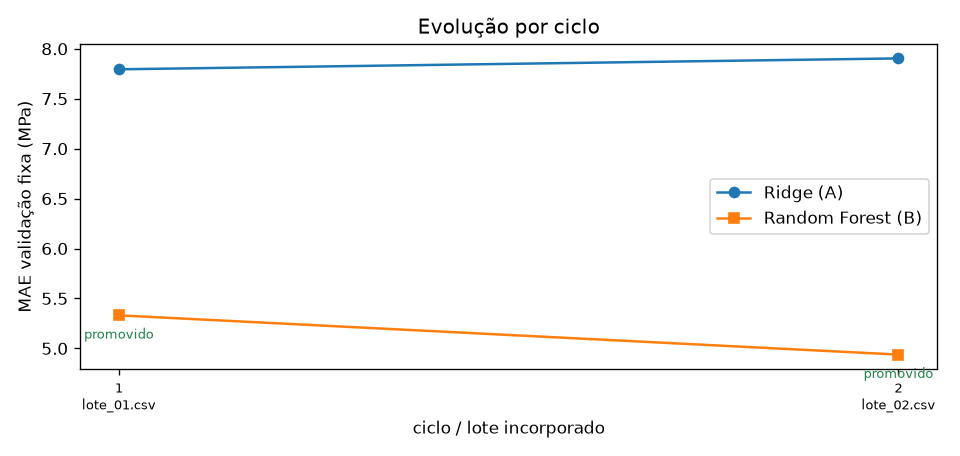

{'cycle_id': 'c20261122T215332Z-gh2',
 'data_version': 'v2-fb30fed2',
 'lote': 'lote_02.csv',
 'n_treino': 436,
 'gatilho': 'schedule',
 'etl': {'linhas_recebidas': 100,
  'removidas_alvo_ausente': 0,
  'removidas_fora_da_faixa': 0,
  'removidas_duplicadas_no_lote': 0,
  'removidas_ja_incorporadas': 0,
  'ausentes_para_imputacao': 3,
  'linhas_aceitas': 100},
 'drift_resumo': '0/9 variáveis com drift (KS, p<0.05)',
 'drift_alerta': False,
 'run_etl': '83745005ae314b3faa374b64a4550dbe',
 'features_eleitas': ['aglomerante_total',
  'log_idade',
  'relacao_agua_cimento',
  'relacao_agua_aglomerante',
  'idade'],
 'criterio_votacao': '>= 2 votos',
 'selecao_por_metodo': {'selectkbest_f_regression': ['aglomerante_total',
   'idade',
   'log_idade',
   'relacao_agua_aglomerante',
   'relacao_agua_cimento'],
  'importancia_random_forest': ['aglomerante_total',
   'idade',
   'log_idade',
   'relacao_agua_aglomerante',
   'relacao_agua_cimento'],
  'rfe_ridge': ['aglomerante_total',
   'agua',

In [4]:
hist = pd.read_csv(HISTORICO_CICLOS)
display(hist)

mlflow = configurar_mlflow(cfg)
runs = mlflow.search_runs(filter_string="tags.etapa = 'treino'", order_by=["start_time ASC"])
tab = runs[["tags.cycle_id", "tags.data_version", "tags.algoritmo", "metrics.val_mae", "metrics.cv_mae_media", "tags.resultado"]]
tab.columns = ["cycle_id", "data_version", "algoritmo", "val_mae", "cv_mae", "resultado"]
print("Histórico recuperado do MLflow (runs de treino):")
display(tab)

if len(hist) >= 1:
    fig, ax = plt.subplots(figsize=(8, 3.8))
    x = range(len(hist))
    ax.plot(x, hist["mae_ridge"], "o-", label="Ridge (A)")
    ax.plot(x, hist["mae_random_forest"], "s-", label="Random Forest (B)")
    for i, d in enumerate(hist["decisao"]):
        if d == "promovido":
            ax.annotate("promovido", (i, min(hist.loc[i, "mae_ridge"], hist.loc[i, "mae_random_forest"])),
                        textcoords="offset points", xytext=(0, -14), ha="center", fontsize=8, color="#1e8449")
    ax.set_xticks(list(x)); ax.set_xticklabels([f"{c}\n{l}" for c, l in zip(range(1, len(hist) + 1), hist["lote"])], fontsize=8)
    ax.set_ylabel("MAE validação fixa (MPa)"); ax.set_xlabel("ciclo / lote incorporado"); ax.legend(); ax.set_title("Evolução por ciclo")
    fig.tight_layout(); fig.savefig(RAIZ / "evidencias" / "evolucao_ciclos.png", dpi=120); plt.close(fig)
    display(Image(str(RAIZ / "evidencias" / "evolucao_ciclos.png")))

with mlflow.start_run(run_name=f"previsoes_{ctx['cycle_id']}"):
    mlflow.set_tags({"cycle_id": ctx["cycle_id"], "data_version": ctx["data_version"], "etapa": "previsoes",
                     "modelo_vigente": f"{manifesto['algoritmo']}@{manifesto['cycle_id']}"})
    mlflow.log_metrics({f"teste_{k}": v for k, v in met_teste.items()})
    mlflow.log_artifact(str(ev / "previsoes_teste.csv"), "previsoes")
salvar_contexto({"teste": met_teste})